# Ocupados a tiempo parcial que querrían trabajar a tiempo completo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "parcialidad-involuntaria"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Ocupados a tiempo parcial que querrían trabajar a tiempo completo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los ocupados a tiempo parcial"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de los ocupados a tiempo parcial que trabajan a tiempo parcial porque no han encontrado un empleo a tiempo completo (tiempo parcial involuntario), según las encuestas de población activa.

**Cómo se lee.** Un valor de 50 significa que la mitad de quienes trabajan a tiempo parcial lo hace porque no encuentra un empleo a jornada completa; la otra mitad lo hace por otros motivos (estudios, cuidados, preferencia).

**Limitaciones.**
- Mide la composición del tiempo parcial, no cuántos ocupados trabajan a tiempo parcial: ese dato, en % de todos los ocupados, va en las notas.
- Qué cuenta como tiempo parcial y cómo se pregunta el motivo cambia entre países. En EE. UU. solo cuenta quien dice que únicamente encontró trabajo a tiempo parcial.
- España y la UE-27 son de 15 a 64 años (Eurostat); la OCDE, EE. UU. y Canadá, del mismo tramo con la OCDE.

## 2. Descarga

- **España y UE-27:** Eurostat `lfsa_eppgai`: ocupados a tiempo parcial involuntario en % del total de ocupados a tiempo parcial, de 15 a 64 años, ambos sexos.
- **OCDE, EE. UU. y Canadá:** OCDE, incidencia del tiempo parcial involuntario (`OECD.ELS.SAE,DSD_INVPT_EMP@DF_INVPT_I`, versión 1.1): ocupados (`_T`) a tiempo parcial involuntario en % del empleo a tiempo parcial (`PT_EMP_PT`), de 15 a 64 años.
- **Solo para las notas:** la serie de España de la OCDE, para compararla con la de Eurostat, y el tiempo parcial involuntario en % de todos los ocupados (`PT_EMP`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, eurostat, oecd
from lib.writer import construir_grafica_data, write_grafica_data

AREAS_OCDE = {"USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW = "OECD.ELS.SAE,DSD_INVPT_EMP@DF_INVPT_I,1.1"
# Dimensiones: país . medida . unidad . sexo . edad . situación profesional . frecuencia
CLAVE = "{AREA}.EMP_INVPT.{UNIDAD}._T.Y15T64._T.A"
FILTROS_EU = {"age": "Y15-64", "sex": "T", "unit": "PC"}

oc, fuentes_oc = oecd.get(DATAFLOW, CLAVE.replace("{UNIDAD}", "PT_EMP_PT"), areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("lfsa_eppgai", FILTROS_EU, desde=DESDE)  # ES y EU27_2020
# Solo para las notas
oc_esp, _ = oecd.get(DATAFLOW, CLAVE.replace("{UNIDAD}", "PT_EMP_PT"), areas={"ESP": "espana"}, desde=DESDE)
sobre_ocupados, _ = oecd.get(DATAFLOW, CLAVE.replace("{UNIDAD}", "PT_EMP"), areas={"ESP": "espana", "OECD": "ocde"}, desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max  count
serie                    
canada  1976  2025     50
eeuu    1998  2025     28
ocde    1983  2025     43
         min   max
serie             
espana  1987  2025
ue27    2002  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes.
2. **Comparación de España** en Eurostat y en la OCDE, para las notas.
3. **Tiempo parcial involuntario en % de todos los ocupados** (España y OCDE, último año), para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def nota_comparacion(texto, a, b, d=1):
    comunes = sorted(set(a.index) & set(b.index))
    dif = (a[comunes] - b[comunes]).abs()
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


# La OCDE publica algún 0 exacto entre años con valores altos (Canadá, 1996): no es un dato real, sino uno que falta
ceros = oc[oc["valor"] == 0]
NOMBRES_OCDE = {"eeuu": "EE. UU.", "canada": "Canadá", "ocde": "la media de la OCDE"}
oc = oc[oc["valor"] != 0]
df = pd.concat([eu, oc], ignore_index=True)
fuentes = [*fuentes_eu, *fuentes_oc]
assert df["valor"].between(0, 100).all(), "porcentaje fuera de rango"

ocu_esp, ocu_ocde = serie(sobre_ocupados, "espana"), serie(sobre_ocupados, "ocde")
a1 = int(min(ocu_esp.index.max(), ocu_ocde.index.max()))
NOTAS = [
    "España y UE-27: Eurostat (lfsa_eppgai), ocupados de 15 a 64 años que trabajan a tiempo parcial porque no han "
    "encontrado un empleo a tiempo completo, en % del total de ocupados a tiempo parcial; UE-27 de composición actual (EU27_2020).",
    "OCDE, EE. UU. y Canadá: OCDE, incidencia del tiempo parcial involuntario (DSD_INVPT_EMP@DF_INVPT_I), ocupados de 15 a "
    "64 años, en % del empleo a tiempo parcial. Qué cuenta como tiempo parcial y cómo se pregunta el motivo depende de la "
    "encuesta de cada país; en EE. UU. solo cuenta quien dice que únicamente encontró trabajo a tiempo parcial.",
    nota_comparacion("Comparación de España en Eurostat y en la OCDE", serie(eu, "espana"), serie(oc_esp, "espana")),
    *[f"La OCDE publica un 0 para {NOMBRES_OCDE[r.serie]} en {int(r.periodo)}, entre años "
      f"con valores mucho más altos: se trata como dato que falta." for r in ceros.itertuples()],
    f"Tiempo parcial involuntario en % de todos los ocupados de 15 a 64 años (OCDE, PT_EMP), en {a1}: España, "
    f"{es(ocu_esp[a1])} %; media de la OCDE, {es(ocu_ocde[a1])} %.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat (lfsa_eppgai), ocupados de 15 a 64 años que trabajan a tiempo parcial porque no han encontrado un empleo a tiempo completo, en % del total de ocupados a tiempo parcial; UE-27 de composición actual (EU27_2020).
- OCDE, EE. UU. y Canadá: OCDE, incidencia del tiempo parcial involuntario (DSD_INVPT_EMP@DF_INVPT_I), ocupados de 15 a 64 años, en % del empleo a tiempo parcial. Qué cuenta como tiempo parcial y cómo se pregunta el motivo depende de la encuesta de cada país; en EE. UU. solo cuenta quien dice que únicamente encontró trabajo a tiempo parcial.
- Comparación de España en Eurostat y en la OCDE: en los 39 años comunes (1987-2025), la diferencia máxima es de 3,4 puntos, en 2011.
- La OCDE publica un 0 para Canadá en 1996, entre años con valores mucho más altos: se trata como dato que falta.
- Tiempo parcial involuntario en % de todos los ocupados de 15 a 64 años (OCDE, PT_EMP), en 2025: España, 6,1 %; media de la OCDE, 2,6 %.


## 4. Visualización

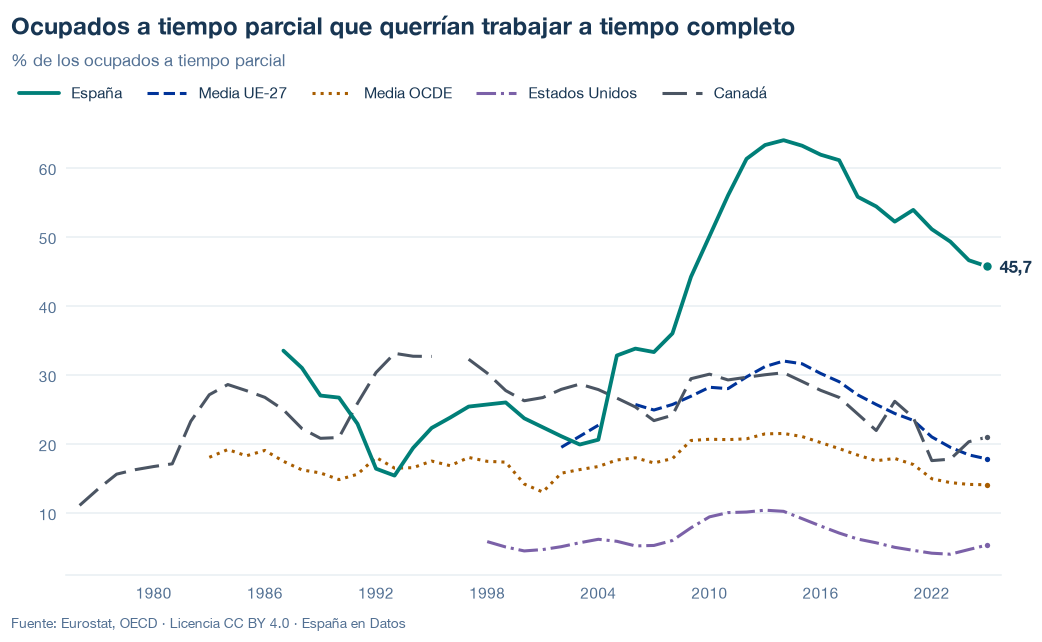

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/parcialidad-involuntaria.json y data/parcialidad-involuntaria.csv


## 6. Fuentes, notas y licencia

- Eurostat, `lfsa_eppgai` (`Y15-64`, `T`, `PC`).
- OCDE, incidencia del tiempo parcial involuntario: `OECD.ELS.SAE,DSD_INVPT_EMP@DF_INVPT_I,1.1` (`EMP_INVPT`, `PT_EMP_PT` y, para las notas, `PT_EMP`, `_T`, `Y15T64`, `_T`, `A`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.